In [4]:
pip install jupyter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 47.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 90.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.9/947.9 kB 43.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [jupyter]


**Mount Drive and load data**

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Update this path to wherever you put the file in Drive
df = pd.read_excel('/content/drive/MyDrive/UDS_ProjectFiles/UDS_Project_Clean.xlsx')
print(f"Loaded: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"\nColumns:\n{list(df.columns)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: 23286 rows, 12 columns

Columns:
['Dummy ID', 'Do you feel Northeastern students have any advantages over non-Northeastern peers?  Please explain.', 'Year', 'CAMPUS_DESC', 'COLLEGE_DESC', 'MAJOR_DESC', 'DEGREE_DESC', 'GENDER_DESC', 'IPEDS_RACE_NAME', 'PROGRAM_DESC', 'STUDENT_LEVEL_DESC', 'APPROX_AGE_AT_GRADUATION']


**Rename the long question column (makes everything easier)**


In [6]:
df.rename(columns={df.columns[1]: 'response_text'}, inplace=True)
print("Renamed column to 'response_text'")
print(df.columns.tolist())

Renamed column to 'response_text'
['Dummy ID', 'response_text', 'Year', 'CAMPUS_DESC', 'COLLEGE_DESC', 'MAJOR_DESC', 'DEGREE_DESC', 'GENDER_DESC', 'IPEDS_RACE_NAME', 'PROGRAM_DESC', 'STUDENT_LEVEL_DESC', 'APPROX_AGE_AT_GRADUATION']


**Cell 3: Basic data profile**

In [7]:
print("=" * 60)
print("BASIC PROFILE")
print("=" * 60)

print(f"\nTotal responses: {len(df)}")
print(f"Blank responses: {df['response_text'].isna().sum()}")
print(f"Duplicate Dummy IDs: {df['Dummy ID'].duplicated().sum()}")
print(f"Duplicate response texts: {df['response_text'].duplicated().sum()}")

print(f"\n--- Year breakdown ---")
print(df['Year'].value_counts().sort_index().to_string())

print(f"\n--- Campus breakdown ---")
print(df['CAMPUS_DESC'].value_counts().to_string())

print(f"\n--- College breakdown ---")
print(df['COLLEGE_DESC'].value_counts().to_string())

print(f"\n--- Student Level breakdown ---")
print(df['STUDENT_LEVEL_DESC'].value_counts().to_string())

print(f"\n--- Gender breakdown ---")
print(df['GENDER_DESC'].value_counts().to_string())

BASIC PROFILE

Total responses: 23286
Blank responses: 45
Duplicate Dummy IDs: 0
Duplicate response texts: 4626

--- Year breakdown ---
Year
2016     912
2017    1411
2018     687
2019    3061
2020    3188
2021    2524
2022    2776
2023    1254
2024    2989
2025    3111
2026    1373

--- Campus breakdown ---
CAMPUS_DESC
Boston                7716
Not Available         4787
Toronto, Canada        448
Seattle, WA            215
Portland, Maine        124
Silicon Valley, CA     104
Vancouver, Canada      104
Charlotte, NC           57
Oakland, CA             24
CA                      15
Toronto                 12
San Jose, CA            11
San Francisco, CA       10
Arlington, VA            7
Miami, FL                1

--- College breakdown ---
COLLEGE_DESC
College of Engineering                       6085
D'Amore-McKim School Business                3083
College of Science                           2909
Bouve College of Hlth Sciences               2458
Khoury Coll of Comp Sciences     

In [8]:
# Check what the duplicates actually are
print("Top 20 repeated response texts:")
print(df['response_text'].value_counts().head(20).to_string())

Top 20 repeated response texts:
response_text
No                      1103
Yes                      947
yes                      267
no                       255
Co-op                    183
No.                       85
Not sure                  76
Not really                76
co-op                     64
Yes.                      63
Coop                      61
NO                        48
Co-op experience          47
Nope                      47
Yes, co-op                47
Maybe                     30
Co-op program             29
Yes because of co-op      26
Work experience           24
YES                       24


**Cell 4: Response length analysis**

In [11]:
df['word_count'] = df['response_text'].astype(str).str.split().str.len()
df['char_count'] = df['response_text'].astype(str).str.len()

print("=" * 60)
print("RESPONSE LENGTH ANALYSIS")
print("=" * 60)

print(f"\nWord count stats:")
print(df['word_count'].describe().round(1).to_string())

print(f"\n--- Short response breakdown ---")
print(f"Blank/NaN:        {df['response_text'].isna().sum()}")
print(f"1 word only:      {(df['word_count'] == 1).sum()}")
print(f"2-3 words:        {df['word_count'].between(2, 3).sum()}")
print(f"4-5 words:        {df['word_count'].between(4, 5).sum()}")
print(f"6-10 words:       {df['word_count'].between(6, 10).sum()}")
print(f"10+ words:        {(df['word_count'] > 10).sum()}")

print(f"\n--- Sample 1-word responses ---")
print(df[df['word_count'] == 1]['response_text'].value_counts().head(10).to_string())

print(f"\n--- Sample 2-3 word responses ---")
sample_short = df[df['word_count'].between(2, 3)]['response_text'].sample(15, random_state=42)
for i, text in enumerate(sample_short, 1):
    print(f"  {i}. {text}")

RESPONSE LENGTH ANALYSIS

Word count stats:
count    23286.0
mean        17.2
std         20.6
min          1.0
25%          4.0
50%         11.0
75%         23.0
max        344.0

--- Short response breakdown ---
Blank/NaN:        45
1 word only:      3724
2-3 words:        1971
4-5 words:        1714
6-10 words:       3726
10+ words:        12151

--- Sample 1-word responses ---
response_text
No       1103
Yes       947
yes       267
no        255
Co-op     183
No.        85
co-op      64
Yes.       63
Coop       61
NO         48

--- Sample 2-3 word responses ---
  1. Co-ops were helpful
  2. The Coop program
  3. No idea
  4. Coop probably
  5. Co-op program
  6. Not sure
  7. Good co-op
  8. Resumes and interviews
  9. No advantage
  10. Co-op experience
  11. Experience from co-ops
  12. Not sure
  13. Yes with co-op
  14. Not sure
  15. work experience


**Cell 5: Check for encoding and text issues**

In [12]:
print("=" * 60)
print("TEXT QUALITY CHECKS")
print("=" * 60)

texts = df['response_text'].dropna().astype(str)

literal_newline = texts.str.contains(r'\\n', regex=True).sum()
print(f"\nLiteral '\\n' in text:  {literal_newline}")

actual_newline = texts.str.contains('\n').sum()
print(f"Actual newlines:       {actual_newline}")

extra_spaces = texts.str.contains(r'  +', regex=True).sum()
print(f"Extra spaces (2+):     {extra_spaces}")

leading_trailing = (texts != texts.str.strip()).sum()
print(f"Leading/trailing space:{leading_trailing}")

non_ascii = texts.str.contains(r'[^\x00-\x7F]', regex=True, na=False).sum()
print(f"Non-ASCII characters:  {non_ascii}")

if non_ascii > 0:
    print(f"\n--- Sample non-ASCII responses ---")
    mask = texts.str.contains(r'[^\x00-\x7F]', regex=True, na=False)
    for i, text in enumerate(texts[mask].head(5), 1):
        print(f"  {i}. {text[:120]}...")

quoted = texts.str.startswith('"').sum()
print(f"\nStart with quote mark: {quoted}")

all_caps = texts.str.match(r'^[A-Z\s!.?]+$').sum()
print(f"ALL CAPS responses:    {all_caps}")

TEXT QUALITY CHECKS

Literal '\n' in text:  0
Actual newlines:       270
Extra spaces (2+):     310
Leading/trailing space:15
Non-ASCII characters:  1005

--- Sample non-ASCII responses ---
  1. I think that most students are doing coops/internships now, and northeastern’s “specialty”—its coop system—is no longer ...
  2. Co-op experiences help students build a resume with legitimate work experience—a very attractive history for recent grad...
  3. Yes! My future goal is to attend dental school, and I already feel like I am ahead of the game because of the experience...
  4. I think the co-op program is good, but it’s extremely competitive and not something that is told to students. It has not...
  5. Yes. I never would’ve found my job if it wasn’t for the co-op experience I had while at Northeastern. This program is so...

Start with quote mark: 1
ALL CAPS responses:    98


**Cell 6: Cleaning**

In [13]:
print("=" * 60)
print("CLEANING")
print("=" * 60)

df_clean = df.copy()
before = len(df_clean)

# 1. Drop blanks
df_clean = df_clean.dropna(subset=['response_text'])
print(f"1. Dropped blanks: {before - len(df_clean)} removed")

# 2. Convert to string
df_clean['response_text'] = df_clean['response_text'].astype(str)

# 3. Fix literal \n to spaces, replace actual newlines with spaces
df_clean['cleaned_text'] = df_clean['response_text'].str.replace(r'\\n', ' ', regex=True)
df_clean['cleaned_text'] = df_clean['cleaned_text'].str.replace('\n', ' ')
print(f"2. Fixed newline encoding")

# 4. Strip leading/trailing whitespace
df_clean['cleaned_text'] = df_clean['cleaned_text'].str.strip()
print(f"3. Stripped leading/trailing whitespace")

# 5. Collapse multiple spaces into one
df_clean['cleaned_text'] = df_clean['cleaned_text'].str.replace(r'\s+', ' ', regex=True)
print(f"4. Collapsed extra spaces")

# 6. Remove surrounding quotes
df_clean['cleaned_text'] = df_clean['cleaned_text'].str.replace(r'^["\']+|["\']+$', '', regex=True).str.strip()
print(f"5. Removed surrounding quote marks")

# 7. Recalculate word count on cleaned text
df_clean['word_count'] = df_clean['cleaned_text'].str.split().str.len()

# 8. Flag short responses
df_clean['is_short'] = df_clean['word_count'] < 5
short_count = df_clean['is_short'].sum()
print(f"6. Flagged {short_count} short responses (under 5 words)")

# 9. Flag usable responses
df_clean['is_usable'] = ~df_clean['is_short']
usable_count = df_clean['is_usable'].sum()
print(f"7. Usable responses for NLP: {usable_count}")

# 10. Standardize college names
college_map = {
    'College of Professional Studies': 'Coll of Professional Studies',
    'Khoury College of Computer Sciences': 'Khoury Coll of Comp Sciences',
    "D'Amore-McKim School of Business": "D'Amore-McKim School Business",
    'Bouve College of Health Sciences': 'Bouve College of Hlth Sciences',
    'College of Arts, Media and Design': 'Coll of Arts, Media & Design',
    'College of Social Sciences and Humanities': 'Coll of Soc Sci & Humanities',
    'Coll of Computer & Info Sci': 'Khoury Coll of Comp Sciences',
}
df_clean['COLLEGE_DESC'] = df_clean['COLLEGE_DESC'].replace(college_map)
print(f"8. Standardized college names ({df_clean['COLLEGE_DESC'].nunique()} unique)")

# 11. Fix truncated student level
df_clean['STUDENT_LEVEL_DESC'] = df_clean['STUDENT_LEVEL_DESC'].replace({
    'Undergrad Spe': 'Undergrad Special'
})
print(f"9. Fixed truncated student level label")

print(f"\n--- Final counts ---")
print(f"Original:          {before}")
print(f"After clean:       {len(df_clean)}")
print(f"Usable (5+ words): {usable_count}")
print(f"Short (flagged):   {short_count}")

CLEANING
1. Dropped blanks: 45 removed
2. Fixed newline encoding
3. Stripped leading/trailing whitespace
4. Collapsed extra spaces
5. Removed surrounding quote marks
6. Flagged 6524 short responses (under 5 words)
7. Usable responses for NLP: 16717
8. Standardized college names (9 unique)
9. Fixed truncated student level label

--- Final counts ---
Original:          23286
After clean:       23241
Usable (5+ words): 16717
Short (flagged):   6524


In [14]:
# Standardize college names
college_map = {
    'College of Professional Studies': 'Coll of Professional Studies',
    'Khoury College of Computer Sciences': 'Khoury Coll of Comp Sciences',
    'D\'Amore-McKim School of Business': 'D\'Amore-McKim School Business',
    'Bouve College of Health Sciences': 'Bouve College of Hlth Sciences',
    'College of Arts, Media and Design': 'Coll of Arts, Media & Design',
    'College of Social Sciences and Humanities': 'Coll of Soc Sci & Humanities',
    'Coll of Computer & Info Sci': 'Khoury Coll of Comp Sciences',
}


df_clean['COLLEGE_DESC'] = df_clean['COLLEGE_DESC'].replace(college_map)
print(f"8. Standardized college names ({len(college_map)} mappings)")
print(f"   Unique colleges now: {df_clean['COLLEGE_DESC'].nunique()}")

8. Standardized college names (7 mappings)
   Unique colleges now: 9


In [15]:
df_clean['STUDENT_LEVEL_DESC'] = df_clean['STUDENT_LEVEL_DESC'].replace({
    'Undergrad Spe': 'Undergrad Special'
})
print(f"Fixed truncated student level label")
print(f"Student levels now:\n{df_clean['STUDENT_LEVEL_DESC'].value_counts().to_string()}")

Fixed truncated student level label
Student levels now:
STUDENT_LEVEL_DESC
Undergraduate                   8943
Graduate                        8834
CPS - Graduate                  1997
Not Available                    912
Law                              606
CPS - Undergraduate Semester     196
Undergrad Specialty Semester     194
Undergrad Special                148


**Cell 7: Visualize response length**

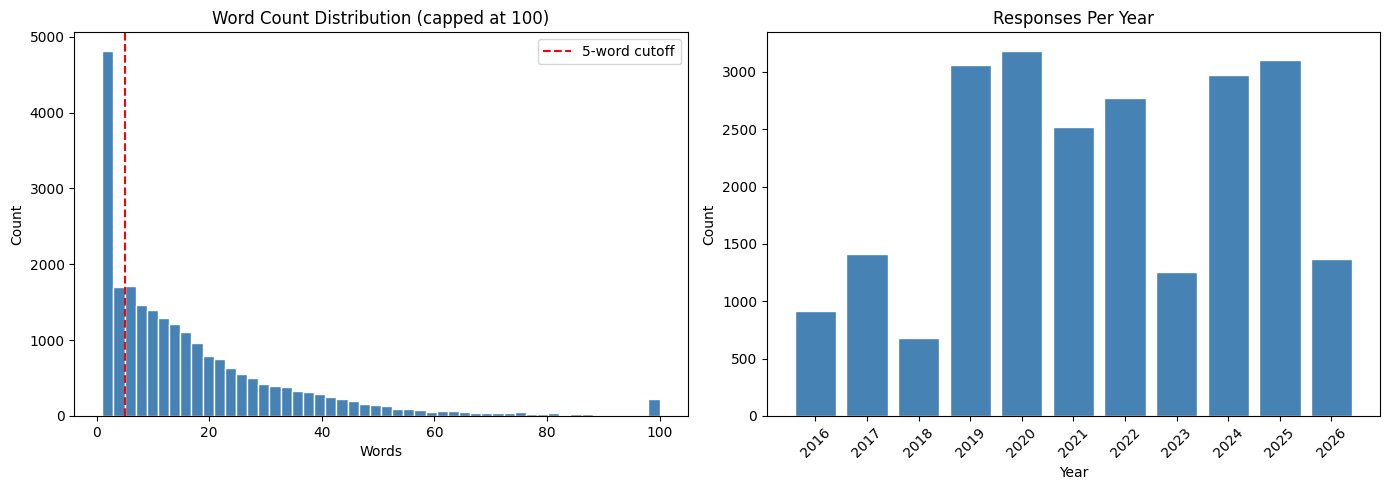

In [16]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_clean['word_count'].clip(upper=100), bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Word Count Distribution (capped at 100)')
axes[0].set_xlabel('Words')
axes[0].set_ylabel('Count')
axes[0].axvline(x=5, color='red', linestyle='--', label='5-word cutoff')
axes[0].legend()

year_counts = df_clean['Year'].value_counts().sort_index()
axes[1].bar(year_counts.index.astype(str), year_counts.values, color='steelblue', edgecolor='white')
axes[1].set_title('Responses Per Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Cell 8: Visualize by college and student level**

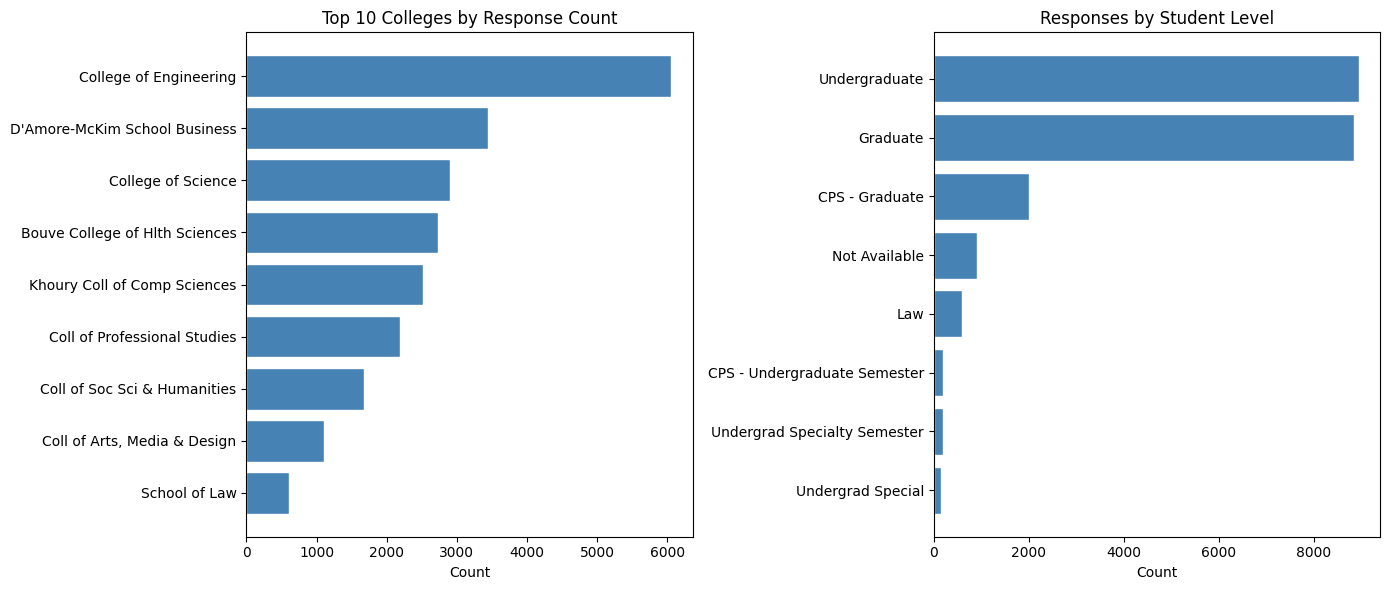

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

college_counts = df_clean['COLLEGE_DESC'].value_counts().head(10)
axes[0].barh(college_counts.index[::-1], college_counts.values[::-1], color='steelblue', edgecolor='white')
axes[0].set_title('Top 10 Colleges by Response Count')
axes[0].set_xlabel('Count')

level_counts = df_clean['STUDENT_LEVEL_DESC'].value_counts()
axes[1].barh(level_counts.index[::-1], level_counts.values[::-1], color='steelblue', edgecolor='white')
axes[1].set_title('Responses by Student Level')
axes[1].set_xlabel('Count')

plt.tight_layout()
plt.show()

**Cell 9: Age distribution**

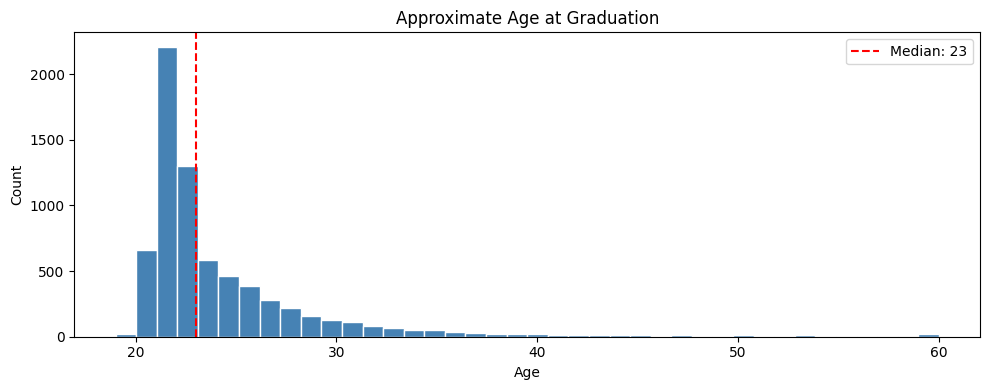

Age stats:
count    7091.0
mean       24.9
std         5.4
min        19.0
25%        22.0
50%        23.0
75%        26.0
max        70.0


In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
ages = df_clean['APPROX_AGE_AT_GRADUATION'].dropna()
ax.hist(ages.clip(upper=60), bins=40, color='steelblue', edgecolor='white')
ax.set_title('Approximate Age at Graduation')
ax.set_xlabel('Age')
ax.set_ylabel('Count')
ax.axvline(x=ages.median(), color='red', linestyle='--', label=f'Median: {ages.median():.0f}')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Age stats:")
print(ages.describe().round(1).to_string())

**Cell 10: Verify cleaning**

In [19]:
print("=" * 60)
print("POST-CLEANING VERIFICATION")
print("=" * 60)

usable = df_clean[df_clean['is_usable']]

print(f"\nUsable responses: {len(usable)}")
print(f"Blanks remaining: {usable['cleaned_text'].isna().sum()}")
print(f"Empty strings remaining: {(usable['cleaned_text'] == '').sum()}")
print(f"Literal '\\n' remaining: {usable['cleaned_text'].str.contains(chr(92) + 'n', regex=False).sum()}")
print(f"Extra spaces remaining: {usable['cleaned_text'].str.contains('  ', regex=False).sum()}")
print(f"Unique colleges: {df_clean['COLLEGE_DESC'].nunique()}")
print(f"Student levels: {df_clean['STUDENT_LEVEL_DESC'].nunique()}")

print(f"\nWord count stats (usable only):")
print(usable['word_count'].describe().round(1).to_string())

print(f"\n--- Sample cleaned responses ---")
for i, row in usable.sample(5, random_state=42).iterrows():
    print(f"\n  ID {row['Dummy ID']} ({row['word_count']} words):")
    print(f"  {row['cleaned_text'][:200]}")

POST-CLEANING VERIFICATION

Usable responses: 16717
Blanks remaining: 0
Empty strings remaining: 0
Literal '\n' remaining: 0
Extra spaces remaining: 0
Unique colleges: 9
Student levels: 8

Word count stats (usable only):
count    16717.0
mean        23.2
std         21.5
min          5.0
25%         10.0
50%         17.0
75%         29.0
max        344.0

--- Sample cleaned responses ---

  ID 6068 (22 words):
  Yes NU works and the advisor helped me secure this coop where I showed my skills and got converted as full time

  ID 19601 (32 words):
  Yes - providing students the opportunity to decide on what type of employment fits them best and look for jobs that they care about and know what they are getting themselves into

  ID 14134 (8 words):
  Yea, coop program is unparalleled for skills development

  ID 5372 (9 words):
  Northeastern was an excellent platform to learn professional courses.

  ID 8397 (29 words):
  I do because we have 6-18 months of additional work experience tha

**Cell 11: Save to Drive**

In [20]:
#full cleaned dataset (all 23,241 rows including short responses)
output_path = '/content/drive/MyDrive/UDS_ProjectFiles/UDS_Cleaned.csv'
df_clean.to_csv(output_path, index=False)
print(f"Saved cleaned data to: {output_path}")
print(f"Total rows: {len(df_clean)}")
print(f"Columns: {list(df_clean.columns)}")

#usable responses (16,717 rows with 5+ words, for embeddings)
usable_path = '/content/drive/MyDrive/UDS_ProjectFiles/UDS_Usable.csv'
df_clean[df_clean['is_usable']].to_csv(usable_path, index=False)
print(f"\nSaved usable responses to: {usable_path}")
print(f"Usable rows: {df_clean['is_usable'].sum()}")

Saved cleaned data to: /content/drive/MyDrive/UDS_ProjectFiles/UDS_Cleaned.csv
Total rows: 23241
Columns: ['Dummy ID', 'response_text', 'Year', 'CAMPUS_DESC', 'COLLEGE_DESC', 'MAJOR_DESC', 'DEGREE_DESC', 'GENDER_DESC', 'IPEDS_RACE_NAME', 'PROGRAM_DESC', 'STUDENT_LEVEL_DESC', 'APPROX_AGE_AT_GRADUATION', 'word_count', 'char_count', 'cleaned_text', 'is_short', 'is_usable']

Saved usable responses to: /content/drive/MyDrive/UDS_ProjectFiles/UDS_Usable.csv
Usable rows: 16717
